In [1]:
# ---------------------------------------------------------
# Practical 3F: Sign Language MNIST Anomaly Detection
# Using Convolutional Autoencoder
# Selected Anomaly: Alphabet Y (Label 24)
# ---------------------------------------------------------

# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [3]:
# Step 2: Load the Sign Language MNIST dataset

train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)

Training Dataset Shape: (27455, 785)
Testing Dataset Shape: (7172, 785)


In [4]:
# Step 3: Separate images and labels

# First column contains alphabet labels
y_train = train_data["label"].values
y_test = test_data["label"].values


In [5]:
# Remaining 784 columns contain pixel values
X_train = train_data.drop("label", axis=1).values
X_test = test_data.drop("label", axis=1).values

print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)


Training Images: (27455, 784)
Testing Images: (7172, 784)


In [6]:
# Step 4: Select the anomaly class

# Label 24 represents alphabet Y
ANOMALY_LABEL = 24


In [7]:
# Step 5: Keep only the remaining 23 classes for training

normal_indices = (y_train != ANOMALY_LABEL)

X_normal = X_train[normal_indices]

print("Normal Training Images:", X_normal.shape)


Normal Training Images: (26337, 784)


In [8]:
# Step 6: Split normal data into training and validation sets

X_train_normal, X_val_normal = train_test_split(
    X_normal,
    test_size=0.1,
    random_state=42
)

print("Training Normal Images:", X_train_normal.shape)
print("Validation Normal Images:", X_val_normal.shape)


Training Normal Images: (23703, 784)
Validation Normal Images: (2634, 784)


In [9]:
# Step 7: Normalize pixel values

# Convert pixel values from 0-255 to 0-1
X_train_normal = X_train_normal.astype("float32") / 255.0
X_val_normal = X_val_normal.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [10]:
# Step 8: Reshape images for CNN

# CNN input format: (samples, height, width, channels)

X_train_normal = X_train_normal.reshape(-1, 28, 28, 1)
X_val_normal = X_val_normal.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Reshaped Training Data:", X_train_normal.shape)
print("Reshaped Testing Data:", X_test.shape)


Reshaped Training Data: (23703, 28, 28, 1)
Reshaped Testing Data: (7172, 28, 28, 1)


In [11]:
# Step 9: Build Convolutional Autoencoder

model = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    # ---------------- ENCODER ----------------

    layers.Conv2D(
        32,
        kernel_size=3,
        strides=2,
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        16,
        kernel_size=3,
        strides=2,
        activation="relu",
        padding="same"
    ),

    # ---------------- DECODER ----------------

    layers.Conv2DTranspose(
        16,
        kernel_size=3,
        strides=2,
        activation="relu",
        padding="same"
    ),

    layers.Conv2DTranspose(
        32,
        kernel_size=3,
        strides=2,
        activation="relu",
        padding="same"
    ),

    # Reconstruct the original image
    layers.Conv2D(
        1,
        kernel_size=3,
        activation="sigmoid",
        padding="same"
    )
])

In [12]:
# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 14, 14, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 7, 7, 16)            │           4,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose (Conv2DTranspose)   │ (None, 14, 14, 16)          │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_1 (Conv2DTranspose) │ (None, 28, 28, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Step 10: Compile the Autoencoder

model.compile(
    optimizer="adam",
    loss="mse"
)

In [14]:
# Step 11: Train using only normal images

history = model.fit(
    X_train_normal,
    X_train_normal,

    epochs=20,
    batch_size=64,

    validation_data=(
        X_val_normal,
        X_val_normal
    ),

    shuffle=True
)

Epoch 1/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - loss: 0.0118 - val_loss: 0.0026
Epoch 2/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0019 - val_loss: 0.0014
Epoch 3/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0013 - val_loss: 0.0011
Epoch 4/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0011 - val_loss: 9.5178e-04
Epoch 5/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 9.2606e-04 - val_loss: 8.4939e-04
Epoch 6/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 8.3555e-04 - val_loss: 8.8871e-04
Epoch 7/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 7.6371e-04 - val_loss: 7.1700e-04
Epoch 8/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 7.1507e-04 - val_loss: 7.4093e-04
Epoch 9/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 6.7386e-04 - val_loss: 6.2560e-04
Epoch 10/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 6.3161e-04 - val_loss: 5.9592e-04
Epoch 11/20
371/371 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 6.0581e-04 - v

In [15]:
# Step 12: Calculate reconstruction error on normal validation data

val_reconstructed = model.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_reconstructed),
    axis=(1, 2, 3)
)


83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


In [16]:
# Set threshold at the 99th percentile
threshold = np.percentile(val_errors, 99)

print("\nAnomaly Detection Threshold:", threshold)


Anomaly Detection Threshold: 0.0012919354


In [17]:
# Step 13: Reconstruct test images

test_reconstructed = model.predict(X_test)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


In [18]:
# Calculate reconstruction error for every test image
test_errors = np.mean(
    np.square(X_test - test_reconstructed),
    axis=(1, 2, 3)
)


In [19]:
# Step 14: Predict anomalies

# Error above threshold = Anomaly
y_pred = (test_errors > threshold).astype(int)


In [20]:
# Actual anomaly:
# Label 24 (Y) = 1
# All other labels = 0

y_test_anomaly = (
    y_test == ANOMALY_LABEL
).astype(int)


In [21]:
# Step 15: Evaluate the model

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_anomaly, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test_anomaly,
        y_pred,
        target_names=["Normal", "Anomaly (Y)"],
        zero_division=0
    )
)

print("Precision:", precision_score(
    y_test_anomaly, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test_anomaly, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_anomaly, y_pred, zero_division=0
))



Confusion Matrix:
[[6806   34]
 [ 332    0]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      1.00      0.97      6840
 Anomaly (Y)       0.00      0.00      0.00       332

    accuracy                           0.95      7172
   macro avg       0.48      0.50      0.49      7172
weighted avg       0.91      0.95      0.93      7172

Precision: 0.0
Recall: 0.0
F1 Score: 0.0


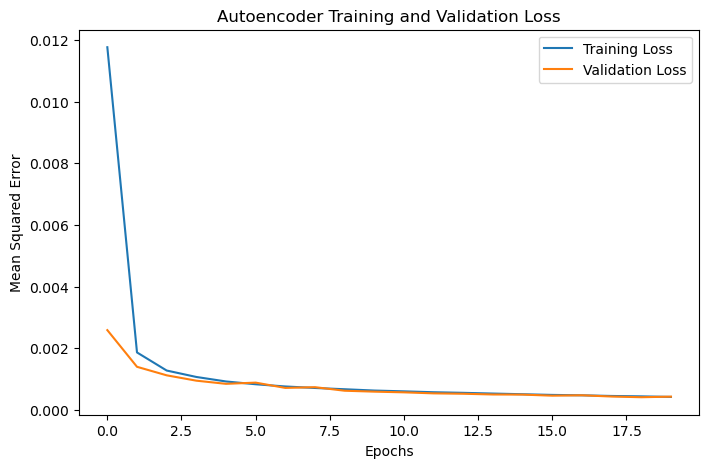

In [22]:
# Step 16: Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()

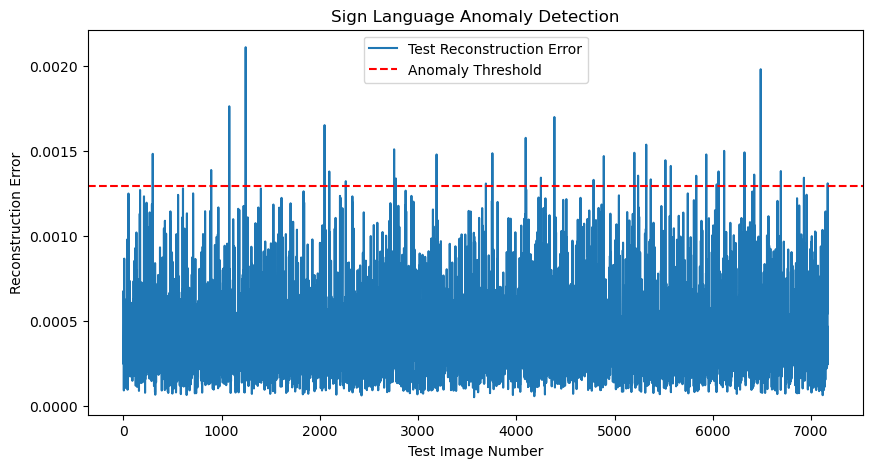

In [23]:
# Step 17: Plot reconstruction errors and threshold

plt.figure(figsize=(10, 5))

plt.plot(test_errors, label="Test Reconstruction Error")

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.title("Sign Language Anomaly Detection")
plt.xlabel("Test Image Number")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()

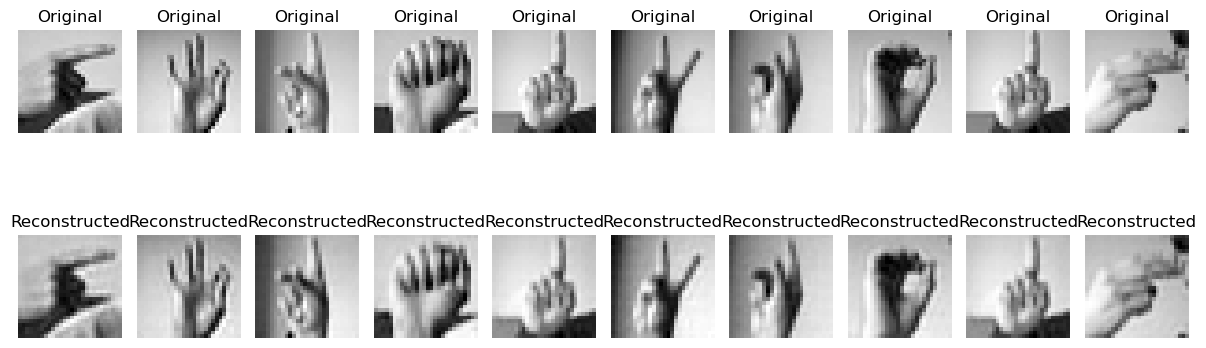

In [24]:
# Step 18: Display some original and reconstructed images

plt.figure(figsize=(12, 5))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        test_reconstructed[i].reshape(28, 28),
        cmap="gray"
    )
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
# Step 19: Display final results

print("\nTotal Test Images:", len(y_test))
print("Actual Y Anomalies:", np.sum(y_test_anomaly))
print("Predicted Anomalies:", np.sum(y_pred))

print("\nPractical Completed Successfully!")



Total Test Images: 7172
Actual Y Anomalies: 332
Predicted Anomalies: 34

Practical Completed Successfully!
